In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import scipy
import sklearn
print('Все библиотеки загрузились')

Все библиотеки загрузились


# Описание кейса из kaggle 

Данный набор данных был любезно предоставлен компанией Olist — крупнейшим оператором, объединяющим продавцов на различных торговых площадках Бразилии. Olist помогает представителям малого бизнеса со всей страны выходить на каналы продаж без лишних сложностей, предлагая единый договор. Продавцы могут реализовывать свои товары через платформу Olist и отправлять их покупателям напрямую, используя логистических партнеров компании. Подробнее — на нашем сайте: www.olist.com

После того как клиент совершает покупку через Olist, продавец получает уведомление о необходимости выполнить заказ. Когда товар доставлен (или наступает ожидаемая дата доставки), покупателю по электронной почте приходит опрос, в котором он может оценить свой опыт покупки и оставить комментарий.

Важное примечание
Один заказ может включать несколько товаров.
Каждый товар может быть предоставлен отдельным продавцом.
Все названия магазинов и партнеров в тексте были заменены на названия великих домов из «Игры престолов».

# Первичный просмотр и предобработка данных Olist
Кейс 1: «Исследование факторов, влияющих на своевременную доставку и удовлетворённость клиентов».

На этом этапе мы загружаем таблицы, смотрим, что в них есть, ищем пропуски, дубликаты и странные значения, и разбираемся, как таблицы связаны между собой. Глубокий анализ — на следующих этапах.

Данные: [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). CSV-файлы нужно положить в папку `data/`. Таблица геолокации большая, поэтому хранится в архиве `olist_geolocation_dataset.zip` — pandas читает его без распаковки.

In [2]:
import pandas as pd

DATA_DIR = 'data/'
files = {
    'orders':    'olist_orders_dataset.csv',
    'items':     'olist_order_items_dataset.csv',
    'reviews':   'olist_order_reviews_dataset.csv',
    'payments':  'olist_order_payments_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'products':  'olist_products_dataset.csv',
    'sellers':   'olist_sellers_dataset.csv',
    'cat_tr':    'product_category_name_translation.csv',
}
df = {name: pd.read_csv(DATA_DIR + f) for name, f in files.items()}

In [3]:
df['geo'] = pd.read_csv(DATA_DIR + 'olist_geolocation_dataset.csv')

## 1. Размер таблиц и столбцы

In [4]:
for name, t in df.items():
    print(f'{name}: {t.shape[0]} строк, {t.shape[1]} столбцов')
    print('   ', list(t.columns))

orders: 99441 строк, 8 столбцов
    ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
items: 112650 строк, 7 столбцов
    ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
reviews: 99224 строк, 7 столбцов
    ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
payments: 103886 строк, 5 столбцов
    ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
customers: 99441 строк, 5 столбцов
    ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
products: 32951 строк, 9 столбцов
    ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'produc

## 2. Пропуски

In [5]:
for name, t in df.items():
    na = t.isna().sum()
    na = na[na > 0]
    if len(na):
        print(f'--- {name}')
        print(na.to_string())

--- orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
--- reviews
review_comment_title      87656
review_comment_message    58247
--- products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2


## 3. Дубликаты

In [6]:
for name, t in df.items():
    print(f'{name}: полных дубликатов строк — {t.duplicated().sum()}')
print()
print('Заказов с несколькими товарами:', (df['items'].groupby('order_id').size() > 1).sum())
print('Заказов с несколькими оплатами:', (df['payments'].groupby('order_id').size() > 1).sum())
print('Заказов с несколькими отзывами:', (df['reviews'].groupby('order_id').size() > 1).sum())

orders: полных дубликатов строк — 0
items: полных дубликатов строк — 0
reviews: полных дубликатов строк — 0
payments: полных дубликатов строк — 0
customers: полных дубликатов строк — 0
products: полных дубликатов строк — 0
sellers: полных дубликатов строк — 0
cat_tr: полных дубликатов строк — 0
geo: полных дубликатов строк — 261831

Заказов с несколькими товарами: 9803
Заказов с несколькими оплатами: 2961
Заказов с несколькими отзывами: 547


## 4. Статусы заказов и даты
Даты хранятся как текст — переводим в формат даты.

In [7]:
orders = df['orders'].copy()
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

print(orders['order_status'].value_counts().to_string())
print()
print('Период покупок:', orders['order_purchase_timestamp'].min().date(), '—', orders['order_purchase_timestamp'].max().date())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Период покупок: 2016-09-04 — 2018-10-17


In [8]:
orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

## 5. Странные значения в датах

In [9]:
dl = orders[orders['order_status'] == 'delivered']
print('Доставленных заказов:', len(dl))
print('Доставлены, но нет даты доставки:', dl['order_delivered_customer_date'].isna().sum())
print('Передача перевозчику раньше покупки:', (dl['order_delivered_carrier_date'] < dl['order_purchase_timestamp']).sum())
print('Доставка покупателю раньше передачи перевозчику:', (dl['order_delivered_customer_date'] < dl['order_delivered_carrier_date']).sum())

Доставленных заказов: 96478
Доставлены, но нет даты доставки: 8
Передача перевозчику раньше покупки: 165
Доставка покупателю раньше передачи перевозчику: 23


## 6. Как связаны таблицы
Главная таблица — заказы (`order_id`). К ней по `order_id` присоединяются товары, оплаты и отзывы, по `customer_id` — покупатели. Товары связаны с карточками товаров (`product_id`) и продавцами (`seller_id`). Геолокация связана с покупателями и продавцами только через префикс почтового индекса (`zip_code_prefix`).

In [10]:
o_ids = set(orders['order_id'])
print('order_id уникален в заказах:', orders['order_id'].is_unique)
print('Товары без заказа:', (~df['items']['order_id'].isin(o_ids)).sum())
print('Отзывы без заказа:', (~df['reviews']['order_id'].isin(o_ids)).sum())
print('Заказы без покупателя:', (~orders['customer_id'].isin(df['customers']['customer_id'])).sum())
print('Товары без продавца:', (~df['items']['seller_id'].isin(df['sellers']['seller_id'])).sum())

order_id уникален в заказах: True
Товары без заказа: 0
Отзывы без заказа: 0
Заказы без покупателя: 0
Товары без продавца: 0


## 7. Таблица геолокации
В таблице координаты (широта и долгота) для префиксов почтовых индексов. Она может пригодиться, чтобы посчитать расстояние между продавцом и покупателем.

In [11]:
geo = df['geo']
print('Строк:', len(geo), '| уникальных индексов:', geo['geolocation_zip_code_prefix'].nunique())
print('Полных дубликатов:', geo.duplicated().sum())
in_brazil = geo['geolocation_lat'].between(-33.8, 5.3) & geo['geolocation_lng'].between(-74, -34.7)
print('Координаты за пределами Бразилии:', (~in_brazil).sum())
zips = set(geo['geolocation_zip_code_prefix'])
print('Покупатели, чьего индекса нет в геолокации:', (~df['customers']['customer_zip_code_prefix'].isin(zips)).sum())
print('Продавцы, чьего индекса нет в геолокации:', (~df['sellers']['seller_zip_code_prefix'].isin(zips)).sum())
print('Примеры написания Сан-Паулу:', list(geo.loc[geo['geolocation_city'].str.contains('paulo') & (geo['geolocation_state'] == 'SP'), 'geolocation_city'].unique()[:4]))

Строк: 1000163 | уникальных индексов: 19015
Полных дубликатов: 261831
Координаты за пределами Бразилии: 42
Покупатели, чьего индекса нет в геолокации: 278
Продавцы, чьего индекса нет в геолокации: 7
Примеры написания Сан-Паулу: ['sao paulo', 'são paulo', 'sãopaulo', 'sa£o paulo']


## Что мы поняли
- Таблицы связываются между собой без потерь.
- В одном заказе может быть несколько товаров, оплат и отзывов — перед объединением их нужно свести к одной строке на заказ, иначе суммы задвоятся.
- Даты нужно переводить из текста в формат даты.
- Для анализа доставки подходят заказы со статусом `delivered` и известной датой доставки.
- В начале (2016) и в конце (сентябрь–октябрь 2018) периода заказов очень мало — эти месяцы, скорее всего, уберём.
- Есть небольшое число заказов со странными датами — нужно решить, удалять ли их.
- У части товаров нет категории.
- В геолокации много дубликатов, есть ошибочные координаты за пределами Бразилии и разное написание городов. На один индекс приходится много точек — если будем считать расстояния, нужно свести их к одной точке на индекс (например, среднее).

**Следующий шаг:** объединить таблицы и создать признаки (опоздание, срок доставки, доставка в другой штат и т. д.). Решить в команде, используем ли расстояние до покупателя.

# Объединение таблиц

In [12]:
df_orders = df['orders']
df_order_items = df['items']
df_order_reviews = df['reviews']
df_order_payments = df['payments']
df_sellers = df['sellers']
df_customers = df['customers']
df_products  = df['products']
df_category_name = df['cat_tr']
df_geo = df['geo']

In [13]:
print('Доставленных заказов:', len(df_orders))

Доставленных заказов: 99441


В этом наборе данных содержится информация о клиенте и его местоположении. 

В нашей системе каждому заказу присваивается уникальный `customer_id`. 
Это означает, что один и тот же клиент может иметь разные идентификаторы для разных заказов. Наличие в наборе данных поля `customer_unique_id` позволяет выявлять клиентов, совершавших повторные покупки в магазине. В противном случае каждый заказ выглядел бы так, будто он сделан отдельным, уникальным клиентом.

Пожалуйста, ознакомьтесь со схемой данных:

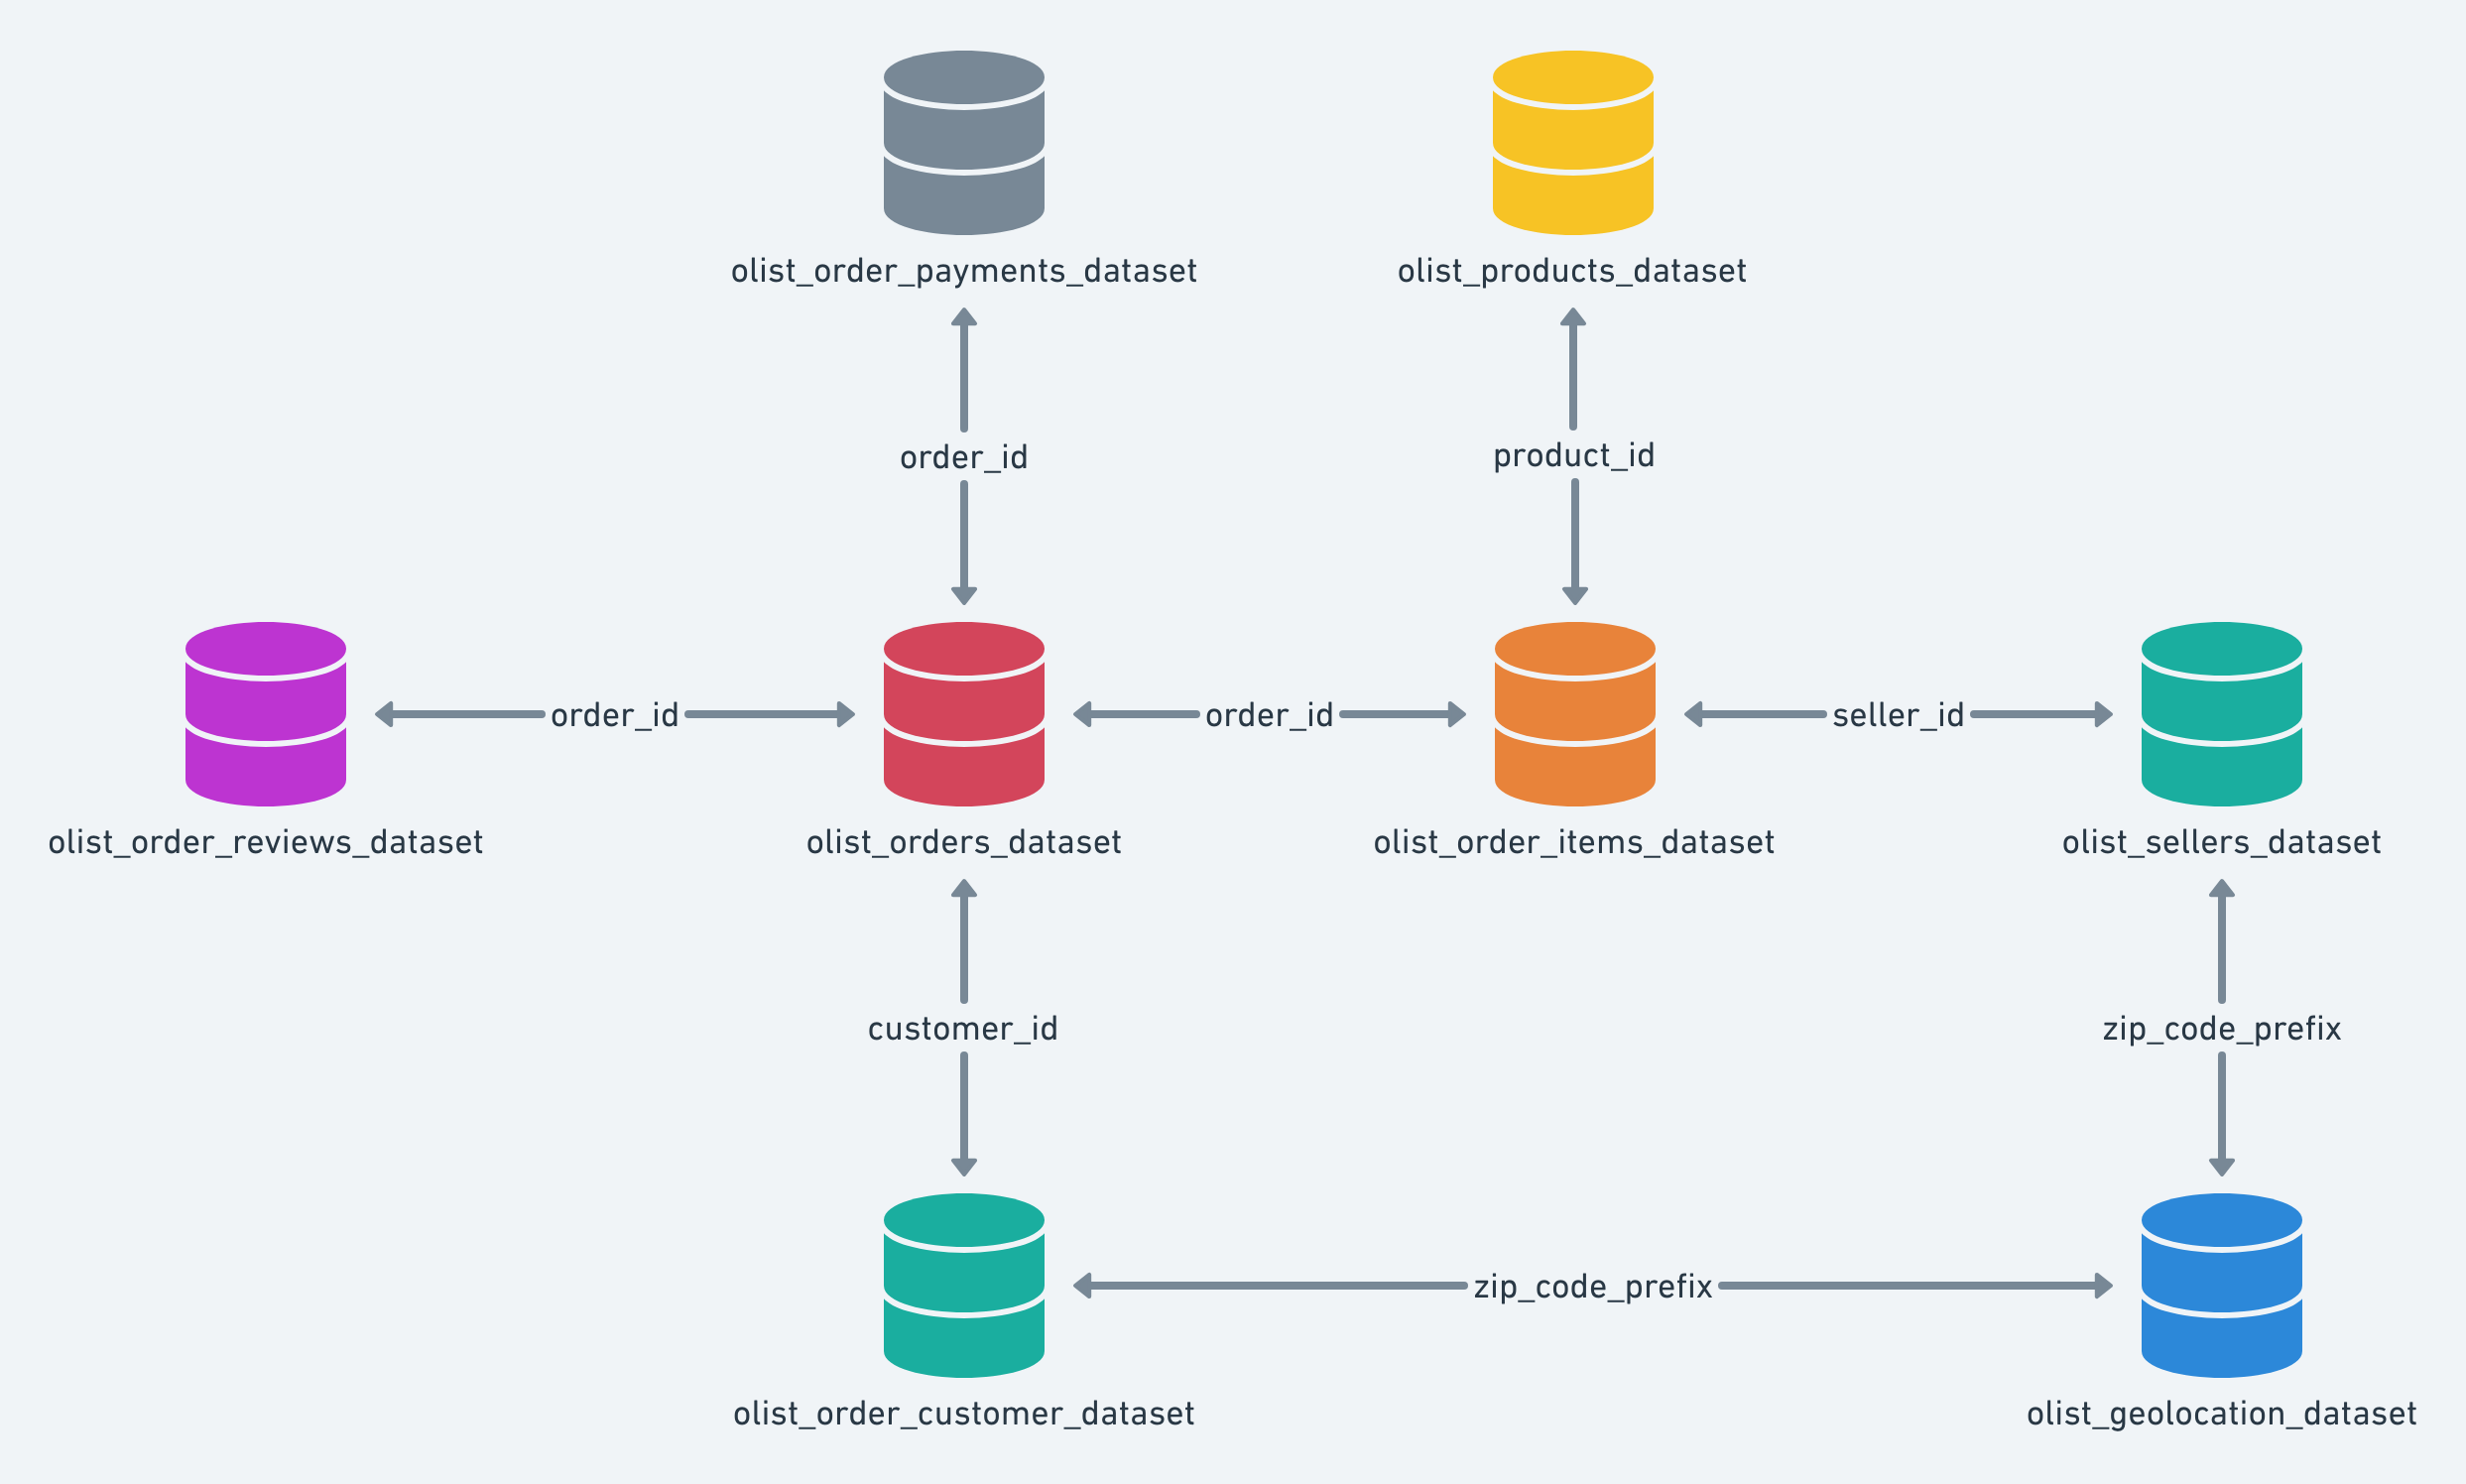

### Соединение заказов и продуктов

In [14]:
df_orders.info()
df_orders.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-04-11 10:48:14,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-08 23:38:46,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [15]:
df_order_items.info()
df_order_items.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [16]:
df_orders_full = df_orders.merge(df_order_items, how='left', on='order_id')
df_orders_full.info()
df_orders_full.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113425 entries, 0 to 113424
Data columns (total 14 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       113425 non-null  object 
 1   customer_id                    113425 non-null  object 
 2   order_status                   113425 non-null  object 
 3   order_purchase_timestamp       113425 non-null  object 
 4   order_approved_at              113264 non-null  object 
 5   order_delivered_carrier_date   111457 non-null  object 
 6   order_delivered_customer_date  110196 non-null  object 
 7   order_estimated_delivery_date  113425 non-null  object 
 8   order_item_id                  112650 non-null  float64
 9   product_id                     112650 non-null  object 
 10  seller_id                      112650 non-null  object 
 11  shipping_limit_date            112650 non-null  object 
 12  price                         

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [17]:
df_orders_products = df_orders_full.merge(df_products, how='left', on='product_id')
df_orders_products.info()
df_orders_products.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113425 entries, 0 to 113424
Data columns (total 22 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       113425 non-null  object 
 1   customer_id                    113425 non-null  object 
 2   order_status                   113425 non-null  object 
 3   order_purchase_timestamp       113425 non-null  object 
 4   order_approved_at              113264 non-null  object 
 5   order_delivered_carrier_date   111457 non-null  object 
 6   order_delivered_customer_date  110196 non-null  object 
 7   order_estimated_delivery_date  113425 non-null  object 
 8   order_item_id                  112650 non-null  float64
 9   product_id                     112650 non-null  object 
 10  seller_id                      112650 non-null  object 
 11  shipping_limit_date            112650 non-null  object 
 12  price                         

,order_item_id,price,freight_value,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,112650.000000,112650.000000,112650.000000,111047.000000,111047.000000,111047.000000,112632.000000,112632.000000,112632.000000,112632.000000
mean,1.197834,120.653739,19.990320,48.775978,787.867029,2.209713,2093.672047,30.153669,16.593766,22.996546
std,0.705124,183.633928,15.806405,10.025581,652.135608,1.721438,3751.596884,16.153449,13.443483,11.707268
min,1.000000,0.850000,0.000000,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,1.000000,39.900000,13.080000,42.000000,348.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,1.000000,74.990000,16.260000,52.000000,603.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,1.000000,134.900000,21.150000,57.000000,987.000000,3.000000,1800.000000,38.000000,20.000000,30.000000
max,21.000000,6735.000000,409.680000,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [18]:
df_orders_products.tail(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
113420,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,1.0,f1d4ce8c6dd66c47bbaa8c6781c2a923,...,174.90,20.10,bebes,52.0,828.0,4.0,4950.0,40.0,10.0,40.0
113421,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,1.0,b80910977a37536adeddd63663f916ad,...,205.99,65.02,eletrodomesticos_2,51.0,500.0,2.0,13300.0,32.0,90.0,22.0
113422,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,1.0,d1c427060a0f73f6b889a5c7c61f2ac4,...,179.99,40.59,informatica_acessorios,59.0,1893.0,1.0,6550.0,20.0,20.0,20.0
113423,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,2.0,d1c427060a0f73f6b889a5c7c61f2ac4,...,179.99,40.59,informatica_acessorios,59.0,1893.0,1.0,6550.0,20.0,20.0,20.0
113424,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00,1.0,006619bbed68b000c8ba3f8725d5409e,...,68.50,18.36,beleza_saude,45.0,569.0,1.0,150.0,16.0,7.0,15.0


In [19]:
df_orders_products.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 161
order_delivered_carrier_date     1968
order_delivered_customer_date    3229
order_estimated_delivery_date       0
order_item_id                     775
product_id                        775
seller_id                         775
shipping_limit_date               775
price                             775
freight_value                     775
product_category_name            2378
product_name_lenght              2378
product_description_lenght       2378
product_photos_qty               2378
product_weight_g                  793
product_length_cm                 793
product_height_cm                 793
product_width_cm                  793
dtype: int64

### Соединение продавцов и геолокации

Таблица гео содержит в себе на 1 код сразу несколько географических координат, что при джойне с другими таблицами сильно размножит строки датасета. 
Предлагаю найти среднюю координату по 1 geolocation_zip_code_prefix

In [20]:
df_geo.info()
df_geo.nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


geolocation_zip_code_prefix     19015
geolocation_lat                717360
geolocation_lng                717613
geolocation_city                 8011
geolocation_state                  27
dtype: int64

In [21]:
df_geo.tail(5)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
1000158,99950,-28.068639,-52.010705,tapejara,RS
1000159,99900,-27.877125,-52.224882,getulio vargas,RS
1000160,99950,-28.071855,-52.014716,tapejara,RS
1000161,99980,-28.388932,-51.846871,david canabarro,RS
1000162,99950,-28.070104,-52.018658,tapejara,RS


In [22]:
df_geo_avg_code = (df_geo.groupby('geolocation_zip_code_prefix', as_index=False)
    .agg(geolocation_lat=('geolocation_lat', 'median'),geolocation_lng=('geolocation_lng', 'median') ))
df_geo_avg_code.nunique()

geolocation_zip_code_prefix    19015
geolocation_lat                18990
geolocation_lng                18990
dtype: int64

In [23]:
df_sellers_geo = df_sellers.merge(df_geo_avg_code,
    how='left', left_on='seller_zip_code_prefix', right_on='geolocation_zip_code_prefix')

In [24]:
df_sellers_geo.tail(10)

,seller_id,seller_zip_code_prefix,seller_city,seller_state,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
3085,9d489893ff6af05029671b785f54b998,13613,leme,SP,13613.0,-22.181937,-47.403982
3086,725af026f869236a8dd0ceb98564d156,35530,claudio,MG,35530.0,-20.441593,-44.765888
3087,f00f5b35d0abcacbdd863672f4bb2c1a,1238,sao paulo,SP,1238.0,-23.542944,-46.653267
3088,7bac63f6603d382cc8d0832eb6c100a8,5713,sao paulo,SP,5713.0,-23.626508,-46.729985
3089,f1fdf2d13186575751aa25876536d85c,5314,sao paulo,SP,5314.0,-23.529228,-46.736541
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR,87111.0,-23.448778,-51.869229
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC,88137.0,-27.626457,-48.673749
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP,4650.0,-23.657838,-46.677462
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS,96080.0,-31.751451,-52.323899
3094,9e25199f6ef7e7c347120ff175652c3b,12051,taubate,SP,12051.0,-23.011362,-45.585644


**Что было сделано в рамках шага** 
    
1. Добавила картинку со связью таблиц и описание данных из каггл
2. Перевела название df к единому формату, чтобы к ним было проще обращаться
3. Объдинила таблицы заказы + продукты (df_orders + df_order_items + df_products) 
Таблица расширилась и теперь 1 строка - это один продукт. Надо быть внимательнее при рассчете сумм. 
При работе по агрегату заказ, лучше обращаться к df_orders
4. Объединила таблицы продавцов и гео локации (df_sellers + df_geo)
Для объединения с усреднила координаты, чтобы не размножать строки и для одного geolocation_zip_code_prefix	было одно значение координат). 


## Гипотезы и дальнейшие шаги

**Гипотезы и дальнейшие шаги**

**Основной вопрос задачи**

Какие факторы влияют на вероятность своевременной доставки заказа? Как можно было бы ее повысить?

**Гипотезы для проверки**

1. На время доставки влияет удаленность продавца от места доставки: чем меньше расстояние доставки, тем вероятнее доставка вовремя. 
2. На время доставки влияет суммарный объем посылки: меньшие по объему товары доставляются быстрее. 
3. На время доставки влияет сам продавец: есть продавцы, которые постоянно задерживают доставку и это является системной проблемой.
4. *С оплатами можно проверить гипотезу, что задержка доставки или отмена доставки прроисходит из-за отсутствия оплаты. Но я бы сделала это вторично. 
5. *Я бы исключила из рассмотрения отзывы. Кажется, что отзывы не могут являться причиной задержки доставки. Скорее может наблюдаться обратная зависимость : отзывы ниже, если есть проблемы с доставкой.


### Гипотеза 3. На время доставки влияет сам продавец

На время доставки влияет сам продавец: есть продавцы, которые постоянно задерживают доставку и это является системной проблемой.

Чтобы проверить гипотезу нужно ответить на несколько вопросов: 
1. Различается ли доля опозданий у разных продавцов?
2. Повторяется ли высокая доля опозданий у часто опаздывающих продавцов в разные месяцы?
3. Есть ли продавцы, у которых высокая доля отмен доставки? (доля заказов в статусах canceled и unavailable)"

#### Подготовка данных для расчета времени доставки по продавцам

In [25]:
#оставляю только нужные мне столбцы для проверки гипотез
df_order_sellers_time = df_orders_products[['order_id', 'order_status', 'product_id', 'seller_id', 'shipping_limit_date', 'order_purchase_timestamp', 'order_approved_at', 	'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']]

In [26]:
# привожу столбцы со временем к формату дат по согласованию с заказчиком
df_order_sellers_time = df_order_sellers_time.copy()

date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date', 
    'shipping_limit_date']

for col in date_cols:
    df_order_sellers_time[col] = (
        pd.to_datetime(df_order_sellers_time[col], errors='coerce')
        .dt.normalize())

In [27]:
# Берём доставленные заказы с известной датой доставки и продавцом
df_orders_delivered_with_date = df_order_sellers_time[
    (df_order_sellers_time['order_status'] == 'delivered') &
    (df_order_sellers_time['order_delivered_customer_date'].notna()) &
    (df_order_sellers_time['seller_id'].notna())].copy()

# Создаю датафрейм, где одна строка на пару продавец — заказ
seller_orders_delivered = df_orders_delivered_with_date.drop_duplicates(subset=['seller_id', 'order_id']).copy()

In [28]:
# Оставляю заказы, в которых не пустая дата доставки дата  и дата создания заказа
seller_orders_on_time = seller_orders_delivered[
    seller_orders_delivered['order_estimated_delivery_date'].notna() &
    seller_orders_delivered['order_purchase_timestamp'].notna()].copy()

In [29]:
# Считаем опоздания
seller_orders_on_time['is_late'] = ( seller_orders_on_time['order_delivered_customer_date'] > seller_orders_on_time['order_estimated_delivery_date'])

In [30]:
# Высчитываем месяц создания заказа
seller_orders_on_time['order_month'] = (seller_orders_on_time['order_purchase_timestamp'].dt.to_period('M'))

In [31]:
# группировка по продавцу и месяцу
seller_monthly = (seller_orders_on_time.groupby(['seller_id', 'order_month'], as_index=False)
    .agg(orders_count=('order_id', 'nunique'), late_orders=('is_late', 'sum'), late_share=('is_late', 'mean')))

seller_monthly.head()

,seller_id,order_month,orders_count,late_orders,late_share
0,0015a82c2db000af6aaaf3ae2ecb0532,2017-09,1,0,0.000000
1,0015a82c2db000af6aaaf3ae2ecb0532,2017-10,2,0,0.000000
2,001cca7ae9ae17fb1caed9dfb1094831,2017-02,5,0,0.000000
3,001cca7ae9ae17fb1caed9dfb1094831,2017-03,11,1,0.090909
4,001cca7ae9ae17fb1caed9dfb1094831,2017-04,13,1,0.076923


#### 1. Различается ли доля опозданий у разных продавцов?

Считаем метрики опоздания по продавцам

In [32]:
seller_late_stats = (
    seller_orders_on_time.groupby('seller_id', as_index=False)
    .agg(
        orders_count=('order_id', 'nunique'),
        late_orders=('is_late', 'sum'),
        late_share=('is_late', 'mean')))

# Убираем продавцов с менее 30 заказов из исследования, чтобы получилось стабильнее
seller_late_30 = seller_late_stats[seller_late_stats['orders_count'] >= 30].copy()



In [33]:
print('Топ-10 продавцов с самым высоким уровнем опозданий')
seller_late_30.sort_values('late_share', ascending=False).head(10)

Топ-10 продавцов с самым высоким уровнем опозданий


,seller_id,orders_count,late_orders,late_share
2766,ede0c03645598cdfc63ca8237acbe73d,43,14,0.325581
2011,ad781527c93d00d89a11eecd9dcad7c1,38,12,0.315789
1000,54965bbe3e4f07ae045b90b0b8541f52,73,22,0.301370
478,2a1348e9addc1af5aaa619b1a3679d6b,48,13,0.270833
1556,835f0f7810c76831d6c7d24c7a646d4d,42,11,0.261905
2211,beadbee30901a7f61d031b6b686095ad,64,15,0.234375
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,96,21,0.218750
2781,ef990a83bbea832f36ebe81376335aa8,43,9,0.209302
1336,712e6ed8aa4aa1fa65dab41fed5737e4,77,16,0.207792
1209,66e0557ecc2b4dbea057e93f215f68d8,30,6,0.200000


Построим общее распределение доли опозданий, чтобы понять насколько сильное отклонение показателей от нормы

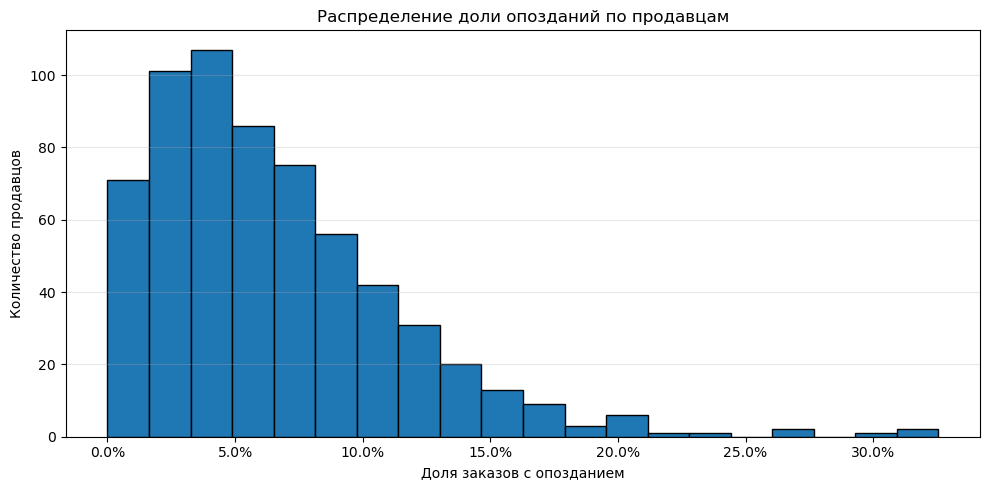

In [34]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.figure(figsize=(10, 5))
plt.hist(seller_late_30['late_share'], bins=20, edgecolor='black')

plt.gca().xaxis.set_major_formatter(PercentFormatter(1))
plt.xlabel('Доля заказов с опозданием')
plt.ylabel('Количество продавцов')
plt.title('Распределение доли опозданий по продавцам')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
seller_late_30['late_share'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

count    627.000000
mean       0.065196
std        0.048919
min        0.000000
25%        0.031250
50%        0.054688
75%        0.090909
90%        0.126257
95%        0.156525
99%        0.216294
max        0.325581
Name: late_share, dtype: float64

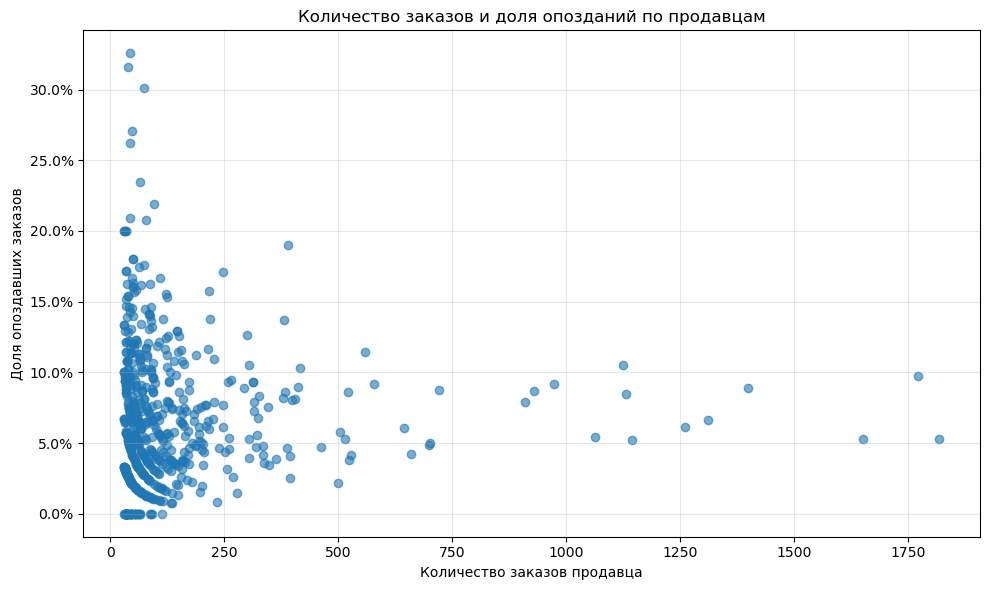

In [36]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.figure(figsize=(10, 6))

plt.scatter(
    seller_late_30['orders_count'],
    seller_late_30['late_share'],
    alpha=0.6
)

plt.xlabel('Количество заказов продавца')
plt.ylabel('Доля опоздавших заказов')
plt.title('Количество заказов и доля опозданий по продавцам')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Среди 627 продавцов с не менее чем 30 доставленными заказами медианная доля опозданий составила 5,5%. 
У примерно 5% продавцов она превысила 15.6%. Эту группу стоит изучить подробнее: проверить количество заказов, повторяемость опозданий по месяцам и этапы доставки.

In [37]:
per_095 = seller_late_30['late_share'].quantile(0.95)

sellers_to_check = seller_late_30[
    seller_late_30['late_share'] > per_095
].sort_values('late_share', ascending=False)

print('Порог:', f'{per_095:.1%}')
print('Продавцов для проверки:', len(sellers_to_check))

sellers_to_check[['seller_id', 'orders_count', 'late_orders', 'late_share']]

Порог: 15.7%
Продавцов для проверки: 32


,seller_id,orders_count,late_orders,late_share
2766,ede0c03645598cdfc63ca8237acbe73d,43,14,0.325581
2011,ad781527c93d00d89a11eecd9dcad7c1,38,12,0.315789
1000,54965bbe3e4f07ae045b90b0b8541f52,73,22,0.301370
478,2a1348e9addc1af5aaa619b1a3679d6b,48,13,0.270833
1556,835f0f7810c76831d6c7d24c7a646d4d,42,11,0.261905
2211,beadbee30901a7f61d031b6b686095ad,64,15,0.234375
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,96,21,0.218750
2781,ef990a83bbea832f36ebe81376335aa8,43,9,0.209302
1336,712e6ed8aa4aa1fa65dab41fed5737e4,77,16,0.207792
739,3fd1e727ba94cfe122d165e176ce7967,35,7,0.200000


#### 2. Повторяется ли высокая доля опозданий у часто опаздывающих продавцов в разные месяцы?

Для корректного сравнения необходимо смотреть на среднюю долю задержек в текущий месяц, так как проблемы могут быть сезонными и сравнивать с общим уровнем за весь период некорректно.

Чтобы корректно определять долю задержек, я считаю долю только для тех продавцов, у которых в рамках месяца было больше 5 заказов. 

In [38]:
# Показатели каждого продавца по месяцам
seller_monthly = (seller_orders_on_time.groupby(['seller_id', 'order_month'], as_index=False)
    .agg(orders_count=('order_id', 'nunique'),
         late_orders=('is_late', 'sum'),
         late_share=('is_late', 'mean')))

# Общая доля опозданий по месяцам: одна строка на заказ
monthly_bench = (seller_orders_on_time.drop_duplicates(subset=['order_id'])
    .groupby('order_month', as_index=False)
    .agg(all_orders=('order_id', 'nunique'),
         overall_late_share=('is_late', 'mean')))

seller_monthly = seller_monthly.merge(
    monthly_bench, on='order_month', how='left', validate='many_to_one')

seller_monthly['above_month_average'] = (
    seller_monthly['late_share'] > seller_monthly['overall_late_share'])

In [39]:
seller_monthly_check = seller_monthly[(seller_monthly['seller_id'].isin(sellers_to_check['seller_id'])) &
    (seller_monthly['orders_count'] >= 5)].copy()

seller_monthly_check.sort_values(['seller_id', 'order_month']).head(5)

,seller_id,order_month,orders_count,late_orders,late_share,all_orders,overall_late_share,above_month_average
20,002100f778ceb8431b7a1020ff7ab48f,2017-10,9,1,0.111111,4478,0.041760,True
21,002100f778ceb8431b7a1020ff7ab48f,2017-11,11,2,0.181818,7288,0.124040,True
22,002100f778ceb8431b7a1020ff7ab48f,2017-12,15,3,0.200000,5513,0.074551,True
409,05f51e13da97139648b8125c31e5f51b,2017-07,8,0,0.000000,3872,0.027893,False
410,05f51e13da97139648b8125c31e5f51b,2017-08,13,0,0.000000,4193,0.029096,False


In [40]:
seller_monthly_summary = (seller_monthly_check.groupby('seller_id', as_index=False).agg(
        months_observed=('order_month', 'nunique'),
        months_above_average=('above_month_average', 'sum'),
        orders_in_months=('orders_count', 'sum'),
        late_orders_in_months=('late_orders', 'sum')
    )
)

seller_monthly_summary['share_months_above_average'] = (
    seller_monthly_summary['months_above_average']
    / seller_monthly_summary['months_observed']
)

seller_monthly_summary.sort_values(
    ['months_above_average', 'months_observed'],
    ascending=[False, False]
)

,seller_id,months_observed,months_above_average,orders_in_months,late_orders_in_months,share_months_above_average
27,e5a3438891c0bfdb9394643f95273d8e,10,6,209,34,0.600000
17,88460e8ebdecbfecb5f9601833981930,9,5,246,42,0.555556
2,06a2c3af7b3aee5d69171b0e14f0ee87,8,5,389,74,0.625000
22,bbad7e518d7af88a0897397ffdca1979,9,4,54,6,0.444444
25,d20b021d3efdf267a402c402a48ea64b,9,4,67,11,0.444444
18,a49928bcdf77c55c6d6e05e09a9b4ca5,5,4,74,12,0.800000
6,2a261b5b644fa05f4f2700eb93544f2c,5,3,40,7,0.600000
24,cac4c8e7b1ca6252d8f20b2fc1a2e4af,5,3,39,8,0.600000
28,ea566164622c6b439516ab18062c42cd,5,3,36,6,0.600000
8,3fd1e727ba94cfe122d165e176ce7967,4,3,33,6,0.750000


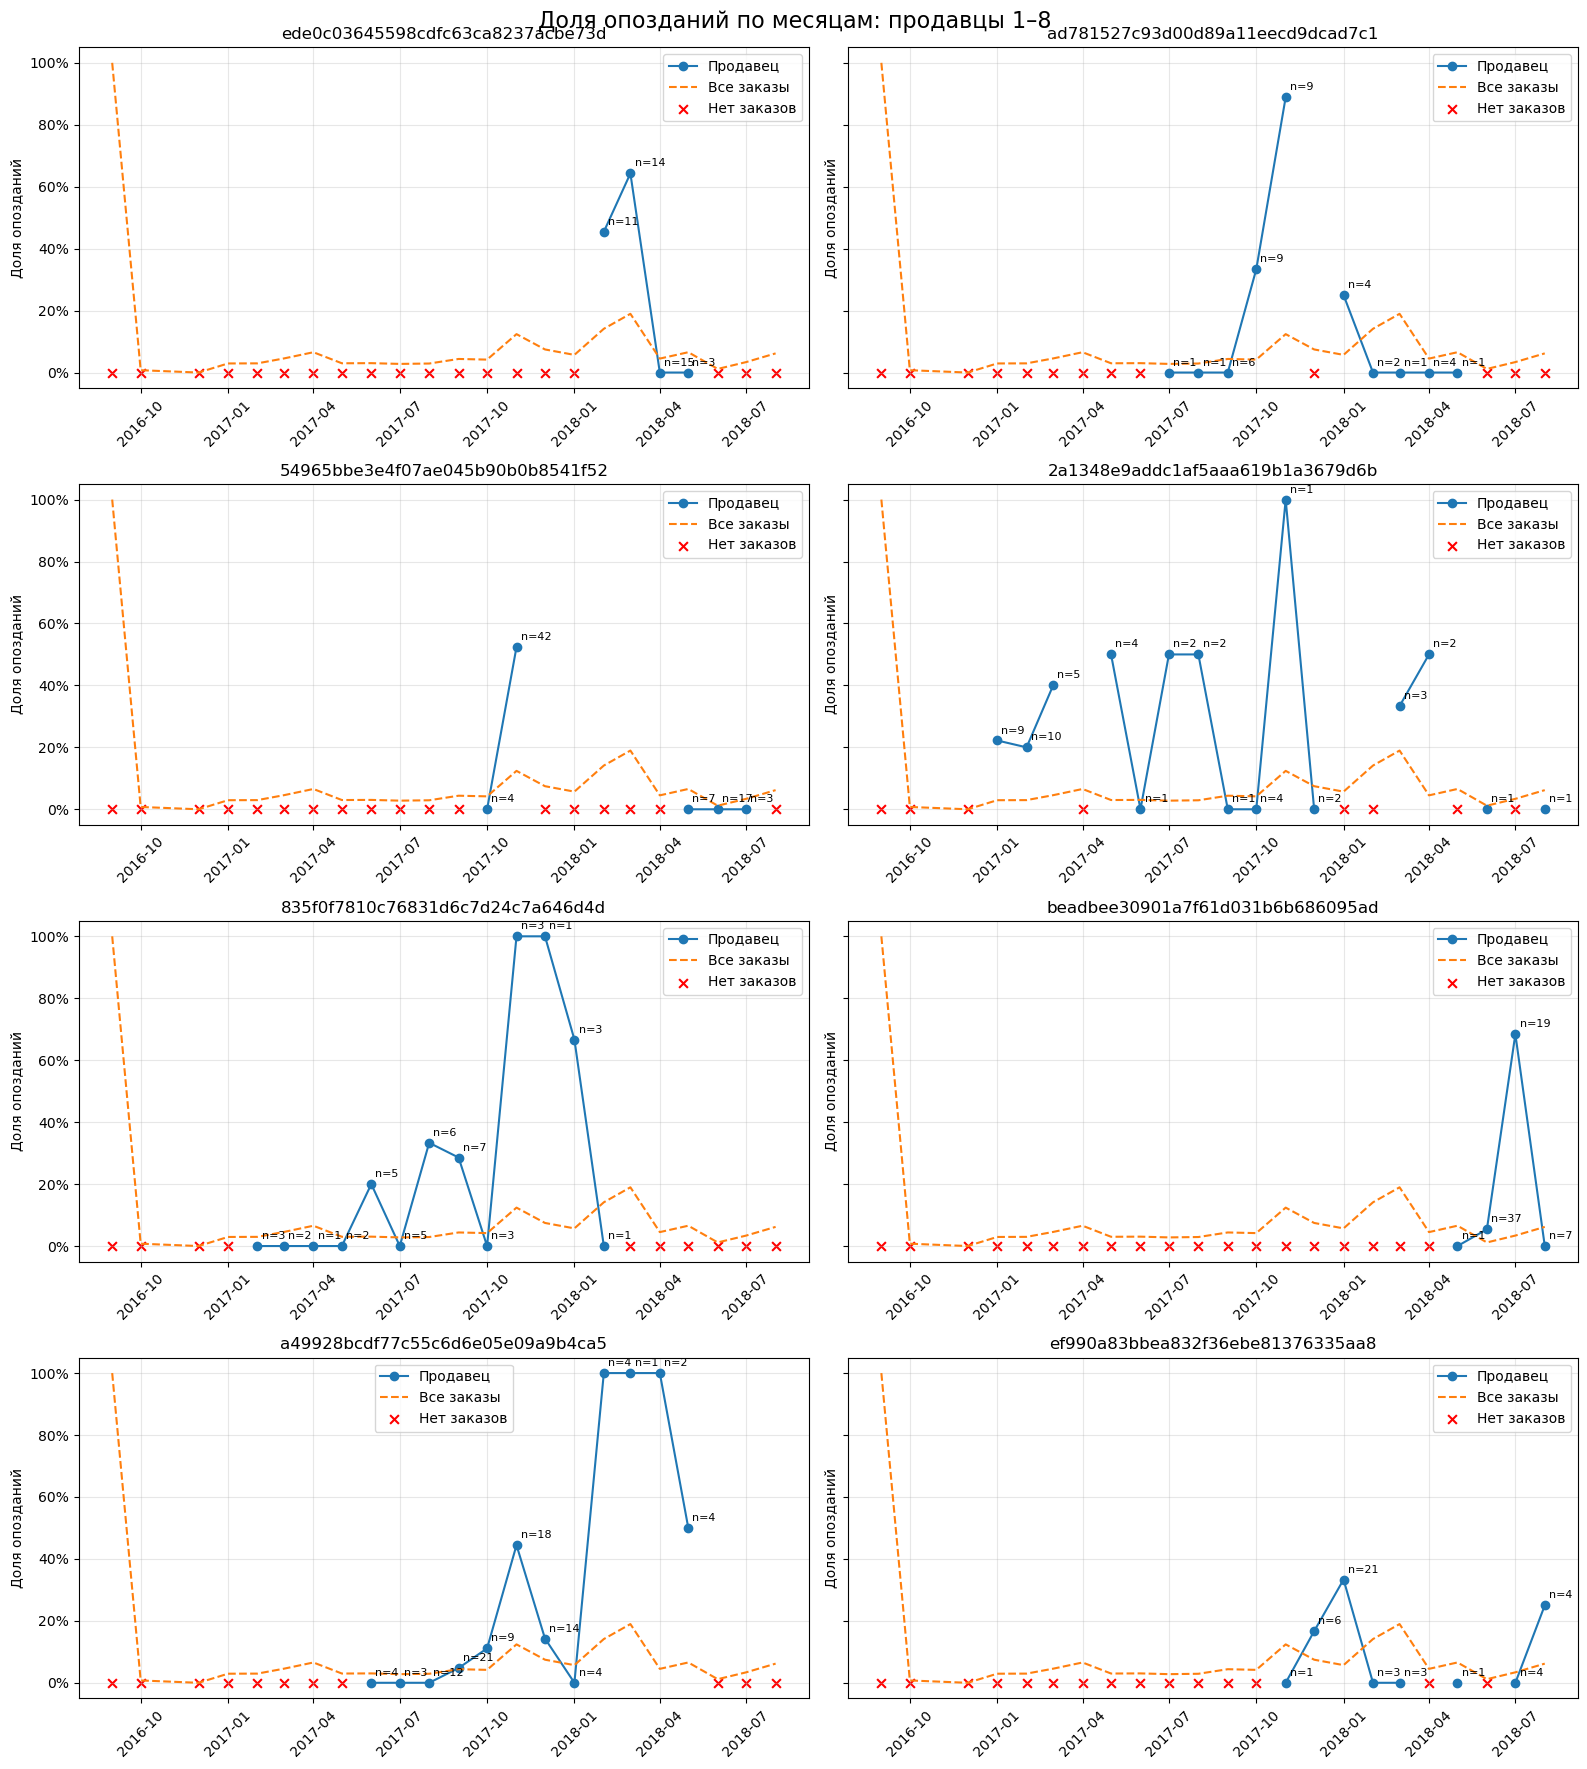

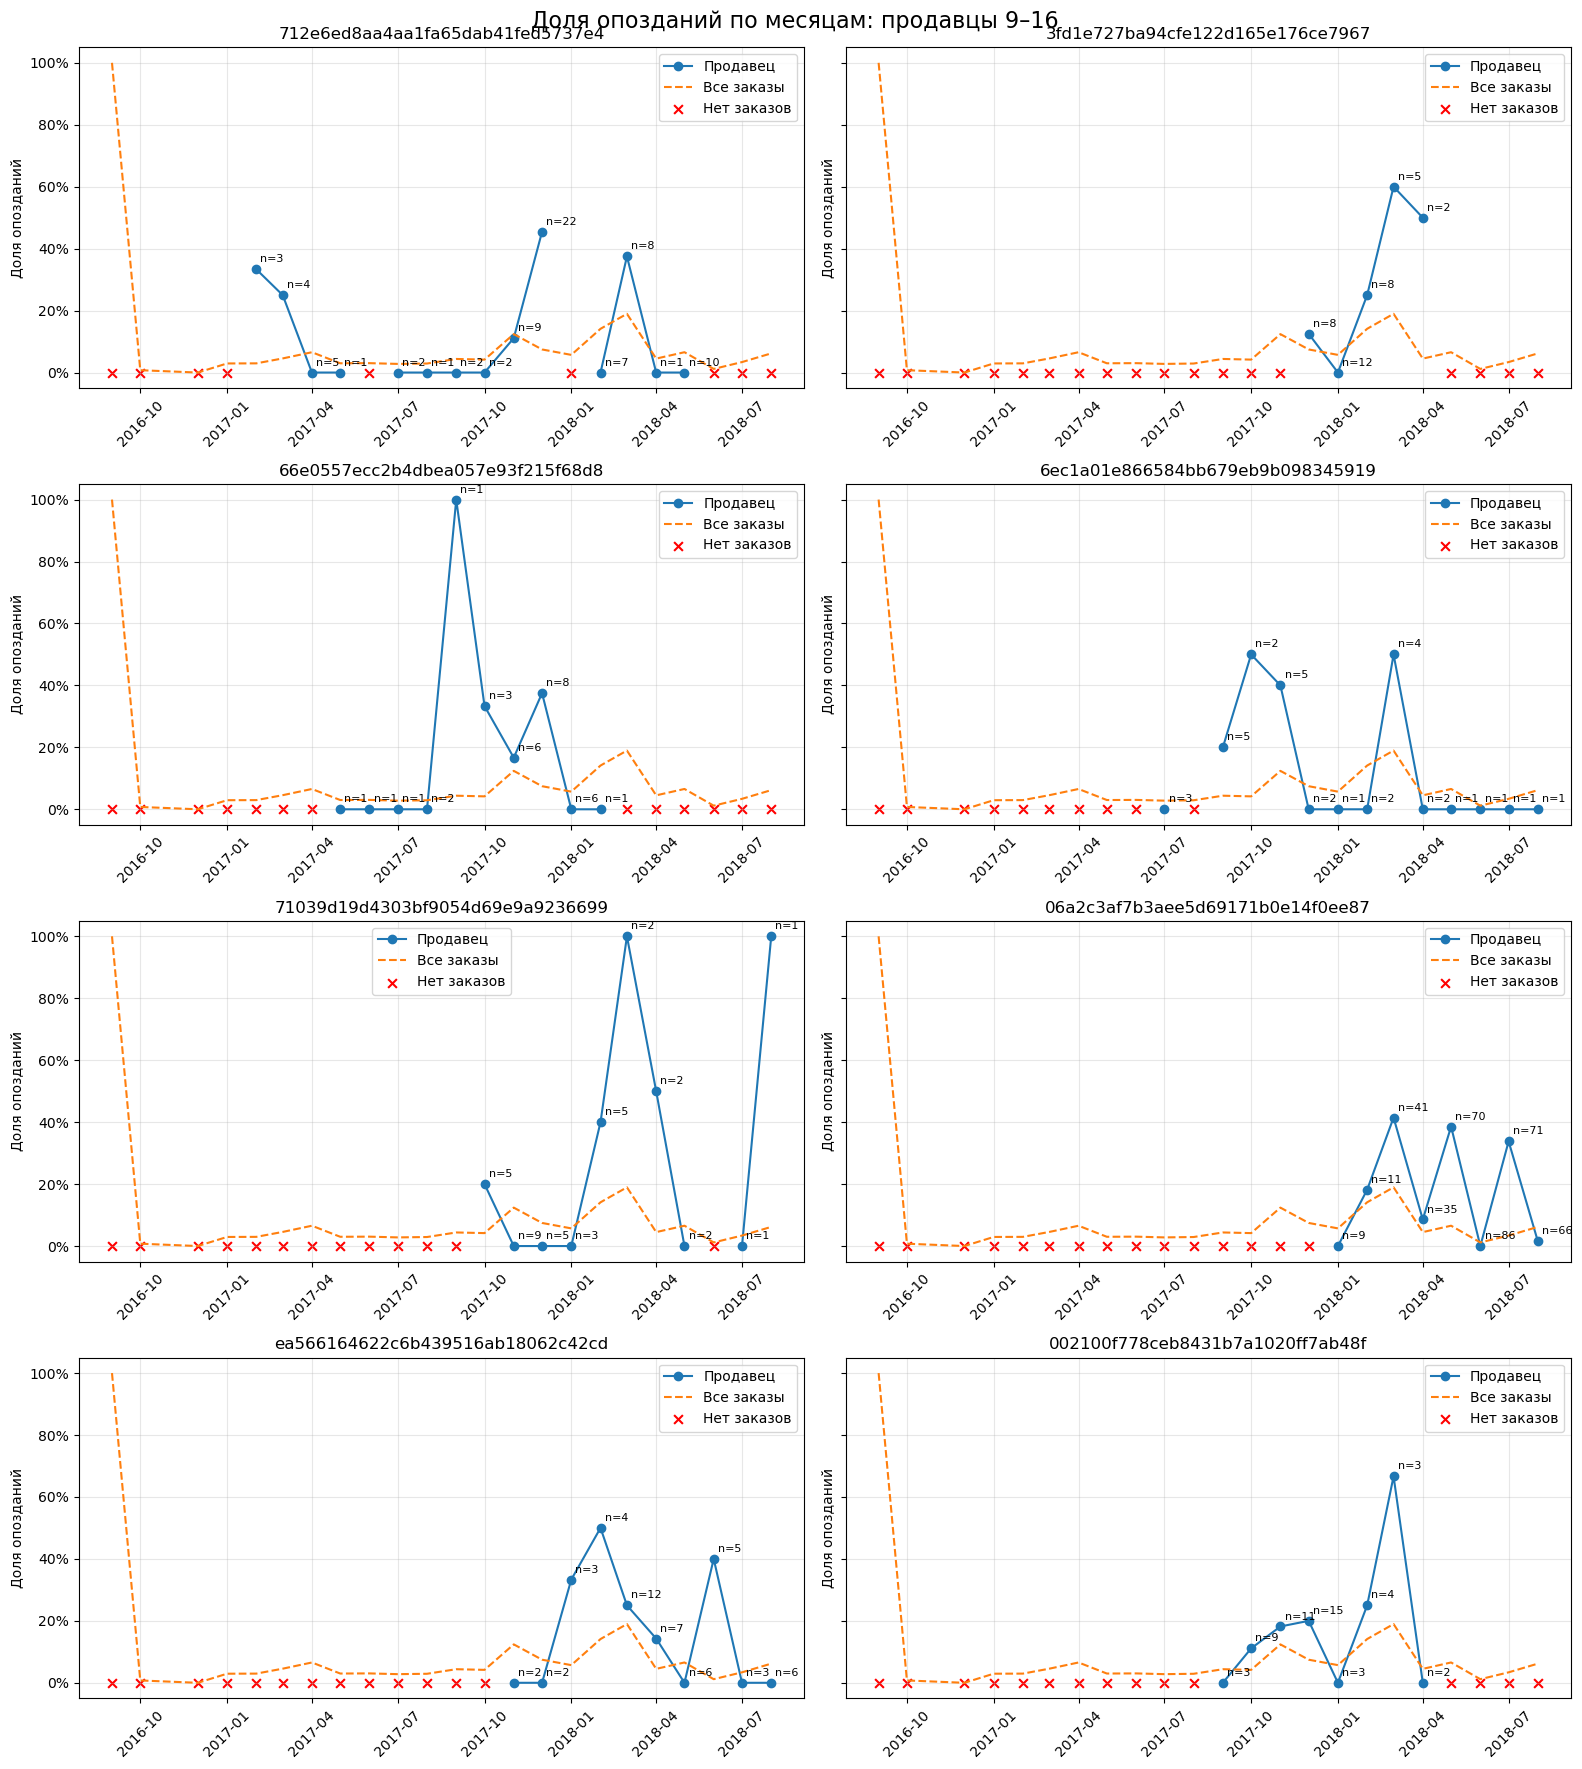

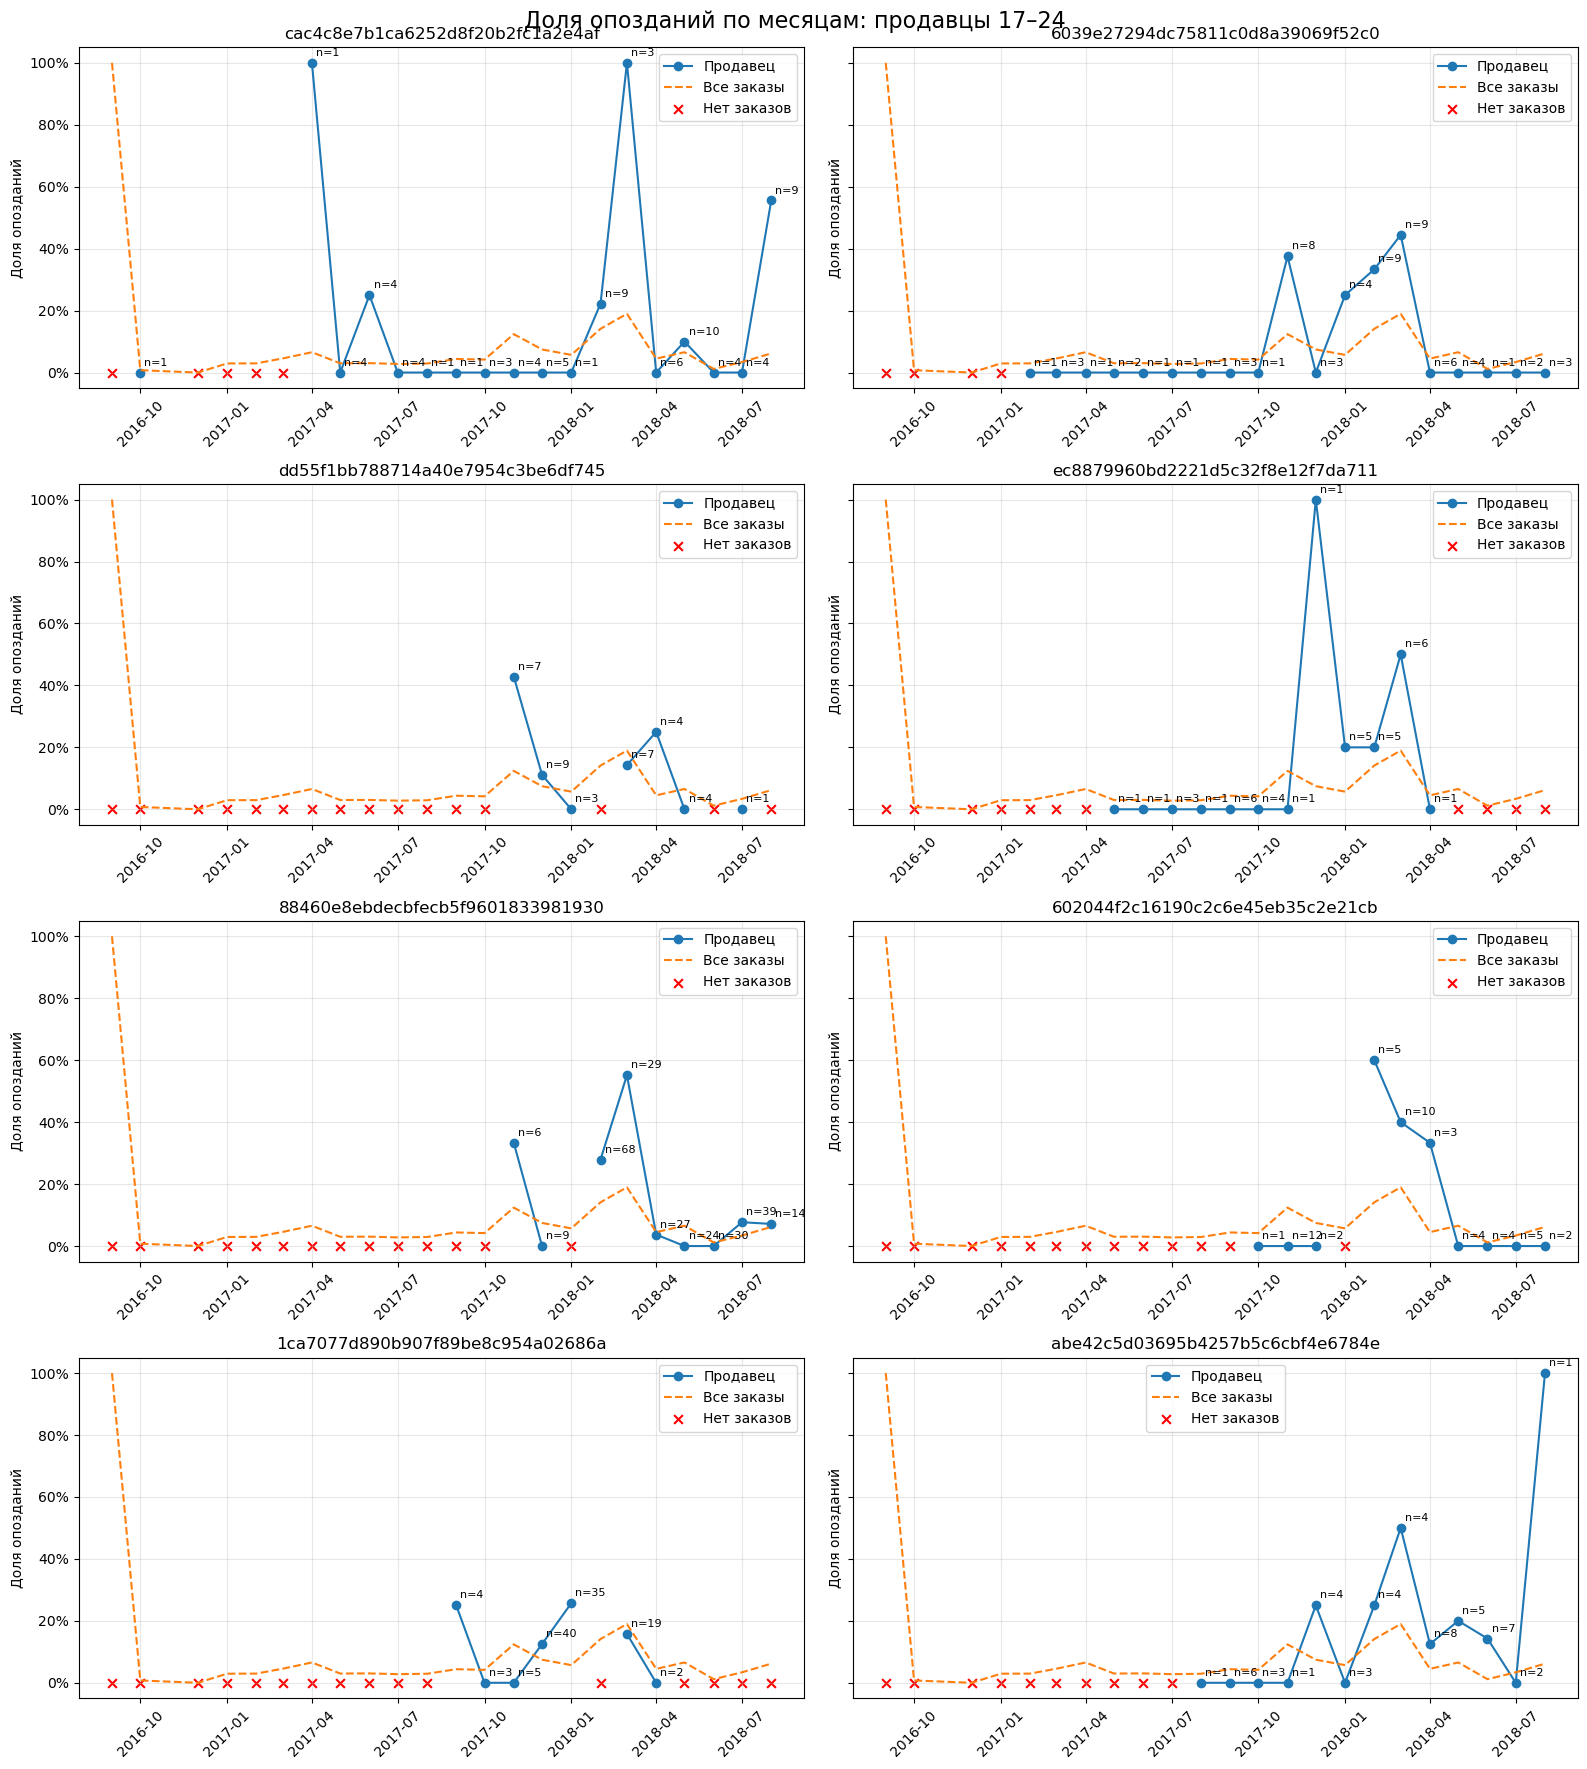

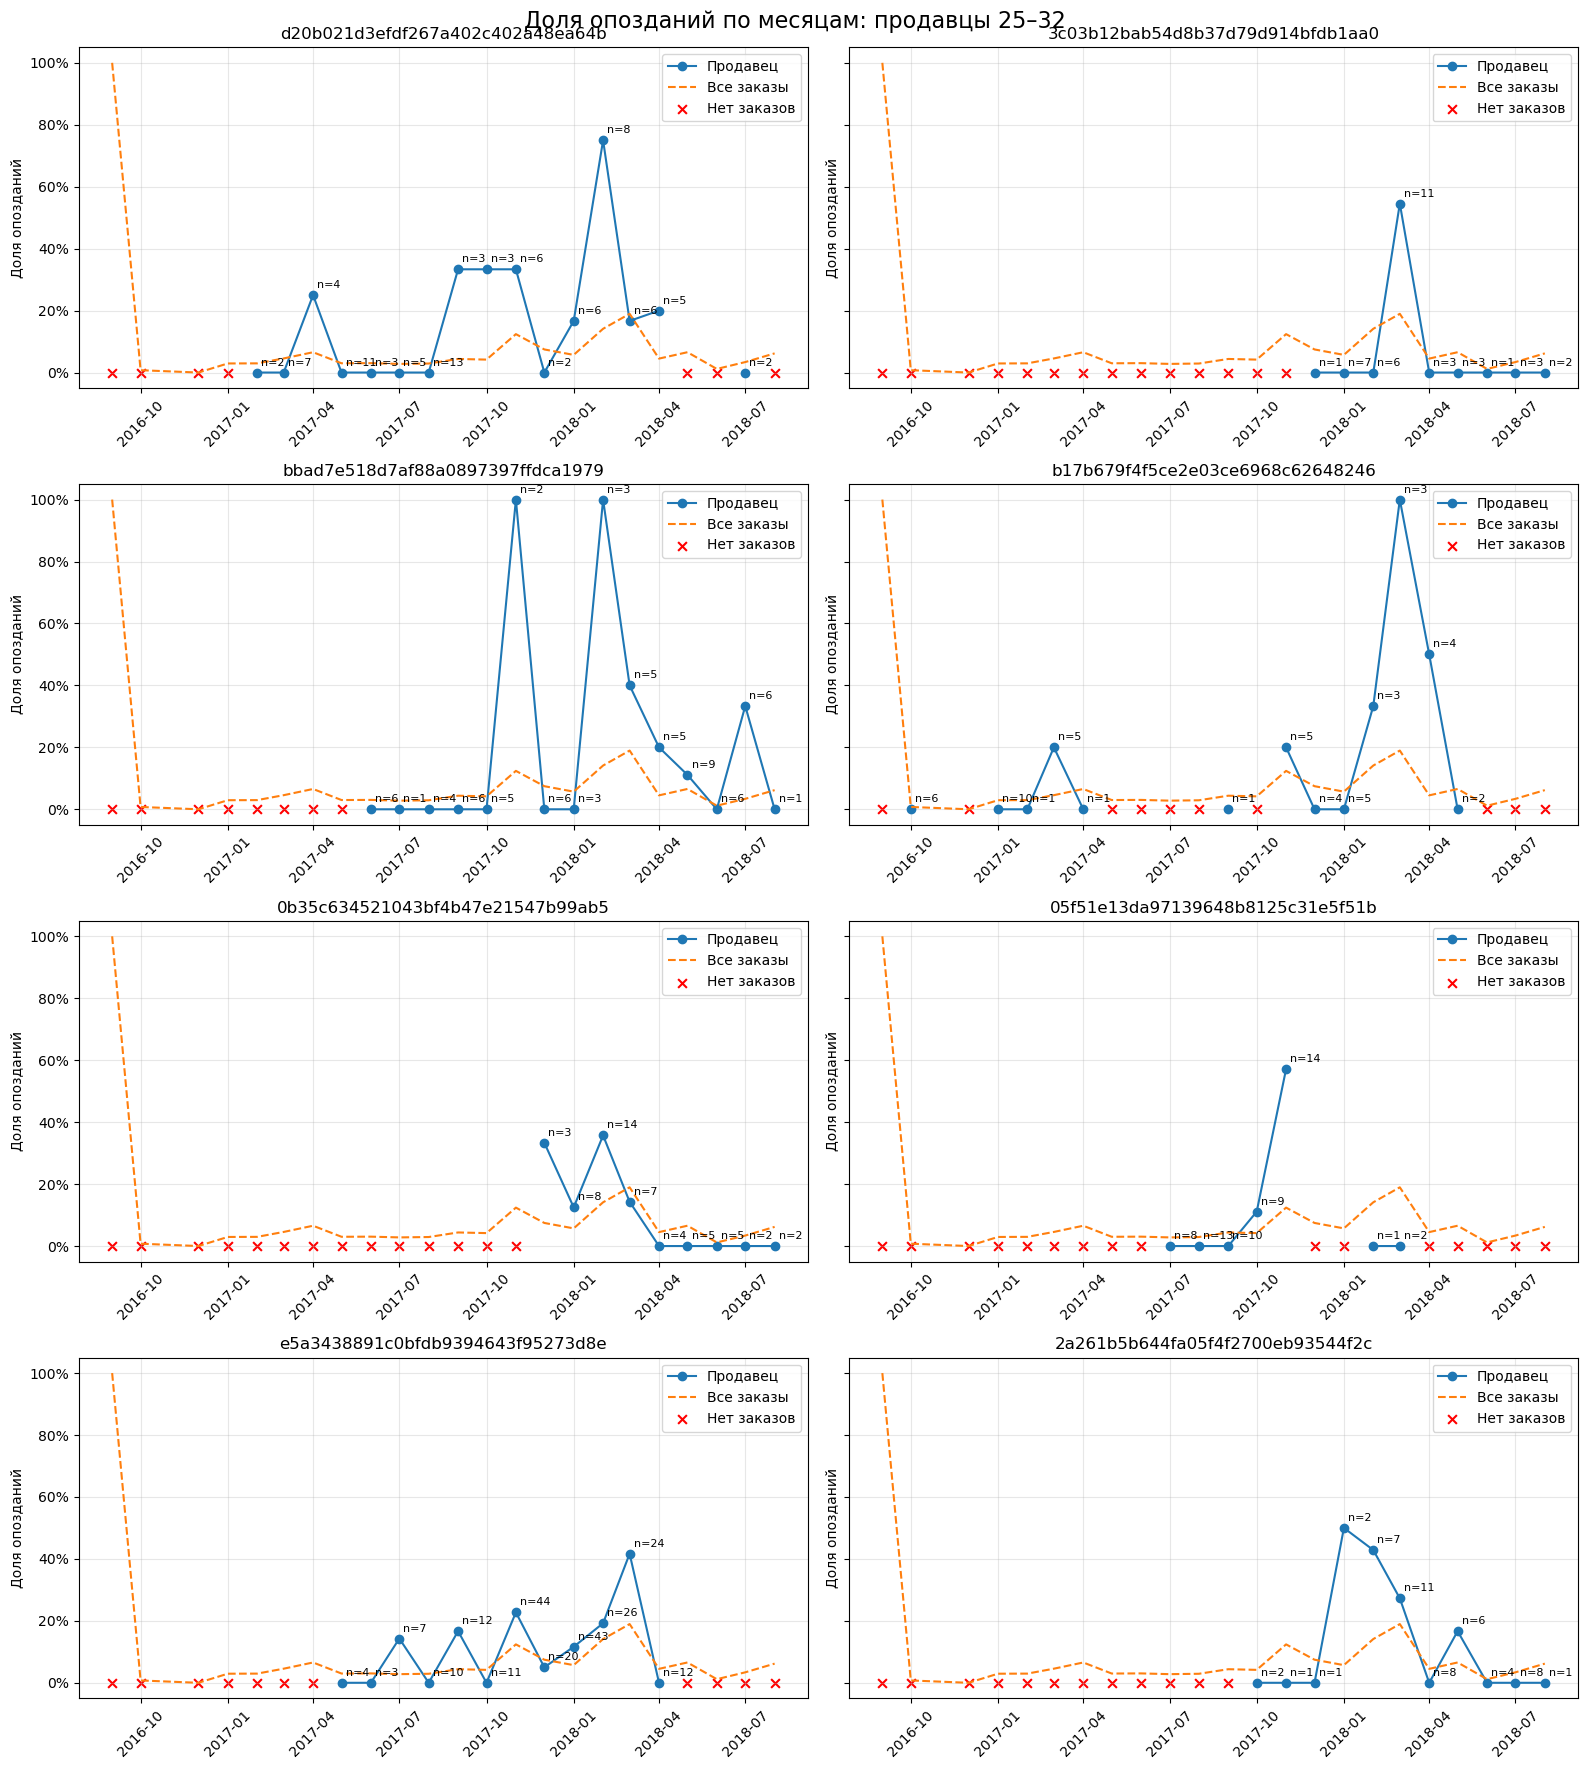

In [41]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Автоматически берём продавцов, отобранных по квантилю
seller_ids = sellers_to_check['seller_id'].tolist()

months = monthly_bench[
    ['order_month', 'overall_late_share']
].sort_values('order_month').copy()

# Показываем по 8 продавцов на одном рисунке
sellers_per_page = 8

for start in range(0, len(seller_ids), sellers_per_page):
    page_ids = seller_ids[start:start + sellers_per_page]

    fig, axes = plt.subplots(4, 2, figsize=(16, 18), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, seller_id in zip(axes, page_ids):
        seller_data = seller_monthly[
            seller_monthly['seller_id'] == seller_id
        ][['order_month', 'orders_count', 'late_share']]

        seller_plot = months.merge(
            seller_data, on='order_month', how='left', validate='one_to_one'
        )

        seller_plot['month_date'] = seller_plot['order_month'].dt.to_timestamp()

        # Линия продавца: пропуски не заменяем на ноль
        ax.plot(
            seller_plot['month_date'], seller_plot['late_share'],
            marker='o', label='Продавец'
        )

        ax.plot(
            seller_plot['month_date'], seller_plot['overall_late_share'],
            linestyle='--', label='Все заказы'
        )

        # Отмечаем месяцы, в которых у продавца не было заказов
        no_orders = seller_plot['orders_count'].isna()

        ax.scatter(
            seller_plot.loc[no_orders, 'month_date'],
            [0] * no_orders.sum(),
            marker='x', color='red', s=40, label='Нет заказов'
        )

        # Подписываем количество заказов в месяце
        for _, row in seller_plot.dropna(subset=['late_share']).iterrows():
            ax.annotate(
                f"n={int(row['orders_count'])}",
                (row['month_date'], row['late_share']),
                xytext=(3, 5), textcoords='offset points', fontsize=8
            )

        ax.set_title(seller_id)
        ax.set_ylabel('Доля опозданий')
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.tick_params(axis='x', rotation=45, labelbottom=True)
        ax.grid(alpha=0.3)
        ax.legend()

    # Скрываем пустые графики на последней странице
    for ax in axes[len(page_ids):]:
        ax.set_visible(False)

    fig.suptitle(
        f'Доля опозданий по месяцам: продавцы {start + 1}–{start + len(page_ids)}',
        fontsize=16
    )
    plt.tight_layout()
    plt.show()

**Итого, что мы наблюдаем из проведенного исследования**

Среди продавцов с не менее чем 30 доставленными заказами с известными датами выделены:
- 32 продавца, чья доля опозданий превышает 95-й процентиль распределения
- У 30 из них было не менее трёх месяцев с пятью и более заказами
- у 19 из этих 30 доля опозданий превышала общий уровень соответствующего месяца более чем в половине рассмотренных месяцев. 

Это повод дополнительно изучить их заказы, регионы и этапы доставки.

#### 3. Есть ли продавцы с высокой долей отмен доставки?  (доля заказов в статусах canceled и unavailable)

Хочу узнать вообще насколько много продавцов не доставляю заказов

И какое распределение по продавцам доставленных и недоставленных заказов. 

Заказ бывает в следующих статусах - 'delivered', 'invoiced', 'shipped', 'processing', 'unavailable', 'canceled', 'created', 'approved'. 
Конечными из них выглядят 
- delivered — доставлен;
- canceled и unavailable — не завершились доставкой.
Остальные статусы промежуточные.
Предлагаю для расчета доли доставленных заказов взять формулу:
share_delivered = delivered / (delivered + canceled + unavailable)


In [42]:
df_orders_products['order_status'].unique()

array(['delivered', 'invoiced', 'shipped', 'processing', 'unavailable',
       'canceled', 'created', 'approved'], dtype=object)

In [43]:
seller_orders_all = (df_order_sellers_time.dropna(subset=['seller_id', 'order_id'])
    .drop_duplicates(subset=['seller_id', 'order_id']).copy())

final_orders = seller_orders_all[seller_orders_all['order_status'].isin(['delivered', 'canceled', 'unavailable'])]

result = (final_orders.groupby(['seller_id', 'order_status'])['order_id'].nunique()
    .unstack(fill_value=0)
    .reindex(columns=['delivered', 'canceled', 'unavailable'], fill_value=0)
    .reset_index())

result['final_orders'] = result['delivered'] + result['canceled'] + result['unavailable']

result['share_delivered'] = result['delivered'] / result['final_orders']

result.sort_values(['delivered', 'share_delivered'], ascending=[False, True]).head(10)

order_status,seller_id,delivered,canceled,unavailable,final_orders,share_delivered
1210,6560211a19b47992c3666cc44a7e94c0,1819,7,0,1826,0.996166
868,4a3ca9315b744ce9f8e9374361493884,1772,2,0,1774,0.998873
2427,cc419e0650a3c5ba77189a1882b7556a,1651,9,0,1660,0.994578
362,1f50f920176fa81dab994f9023523100,1399,1,0,1400,0.999286
2585,da8622b14eb17ae2831f4ac5b9dab84a,1311,0,0,1311,1.000000
1789,955fee9216a65b617aa5c0531780ce60,1261,1,0,1262,0.999208
1475,7a67c85e85bb2ce8582c35f2203ad736,1145,1,0,1146,0.999127
2773,ea8482cd71df3c1969d7b9473ff13abc,1132,1,0,1133,0.999117
844,4869f7a5dfa277a7dca6462dcf3b52b2,1124,1,0,1125,0.999111
721,3d871de0142ce09b7081e2b9d1733cb1,1064,4,0,1068,0.996255


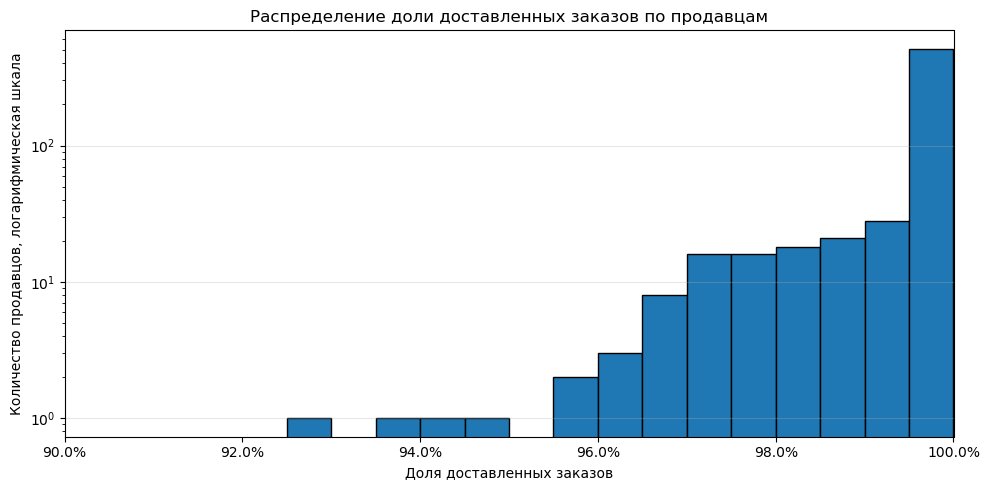

Всего продавцов с 30+ заказами: 628
С долей ниже 90%: 0


In [44]:
sellers_filtered = result[result['final_orders'] >= 30]

plt.figure(figsize=(10, 5))

plt.hist(sellers_filtered['share_delivered'], bins=np.arange(0.90, 1.001, 0.005), edgecolor='black')

plt.xlim(0.90, 1.00)
plt.yscale('log')
plt.gca().xaxis.set_major_formatter(PercentFormatter(1))

plt.xlabel('Доля доставленных заказов')
plt.ylabel('Количество продавцов, логарифмическая шкала')
plt.title('Распределение доли доставленных заказов по продавцам')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('Всего продавцов с 30+ заказами:', len(sellers_filtered))
print('С долей ниже 90%:', (sellers_filtered['share_delivered'] < 0.90).sum())

In [45]:
# продавцы с 30+ заказов с минимальной долей доставок по заказам. 
min_sellers_filtered = sellers_filtered[sellers_filtered['share_delivered'] <= 0.95]
min_sellers_filtered 

order_status,seller_id,delivered,canceled,unavailable,final_orders,share_delivered
415,23d7c96d4a1160db1c726b248601b25a,50,3,0,53,0.943396
853,4917cee8d902e13428c3ec4b1ca6f315,31,2,0,33,0.939394
1373,718539d38d07dd351c76db862760e2e2,35,2,0,37,0.945946
2193,bacb1f0ed56ad24198f5810d2b3fe9a5,38,3,0,41,0.926829


Среди продавцов с не менее чем 30 заказами с выбранными итоговыми статусами обнаружены четыре продавца, у которых доля доставленных заказов составила не более 95%. Для них стоит дополнительно изучить причины отмен. 

#### Вывод по гипотезе 3 - влияние на срок доставки самого продавца

Мы не можем отвергать влияние продавца на сроки задержки, тк доля задержек разделичается между продавцами. 
Так же оно не является стабильным по месяцам. 

- В общей подготовленной выборке — 96 470 уникальных доставленных заказов с известными датами. Из них 6 534, или 6,77%, пришли позже обещанного дня.
- Среди 627 продавцов с не менее чем 30 такими заказами медианная доля опозданий продавца — 5,5%. 
- 32 продавца имеют долю отмен выше 15,7% (95 процентиль)
- У 30 из 32 нашлось как минимум три месяца с пятью и более заказами. У 19 из этих 30 доля опозданий превышала общий уровень соответствующего месяца более чем в половине таких месяцев.

Статистическая надёжность различий и влияние других факторов пока не проверены, поэтому гипотеза о влиянии самого продавца требует дальнейшего исследования.